# 第四章 从头实现GPT模型进行文本生成

In [1]:
# 指定小型GPT-2模型的配置
GPT_CONFIG_124M = {
    "vocab_size": 50257,  # 词汇表大小
    "context_length": 1024,  # 上下文长度
    "emb_dim": 768,  # 嵌入维度
    "n_heads": 12,  # 注意力头的数量
    "n_layers": 12,  # 层数
    "drop_rate": 0.1,  # dropout率
    "qkv_bias": False  # 查询-键-值偏置
}

## 层归一化
层归一化的主要思想是调整神经网络层的激活（输出），使其均值为0且方差（单位方差）为1。这种调整有助于加速权重的有效收敛，并确保训练过程的一致性和可靠性。在GPT-2和当前的Transformer架构中，层归一化通常在多头注意力模块的前后进行。
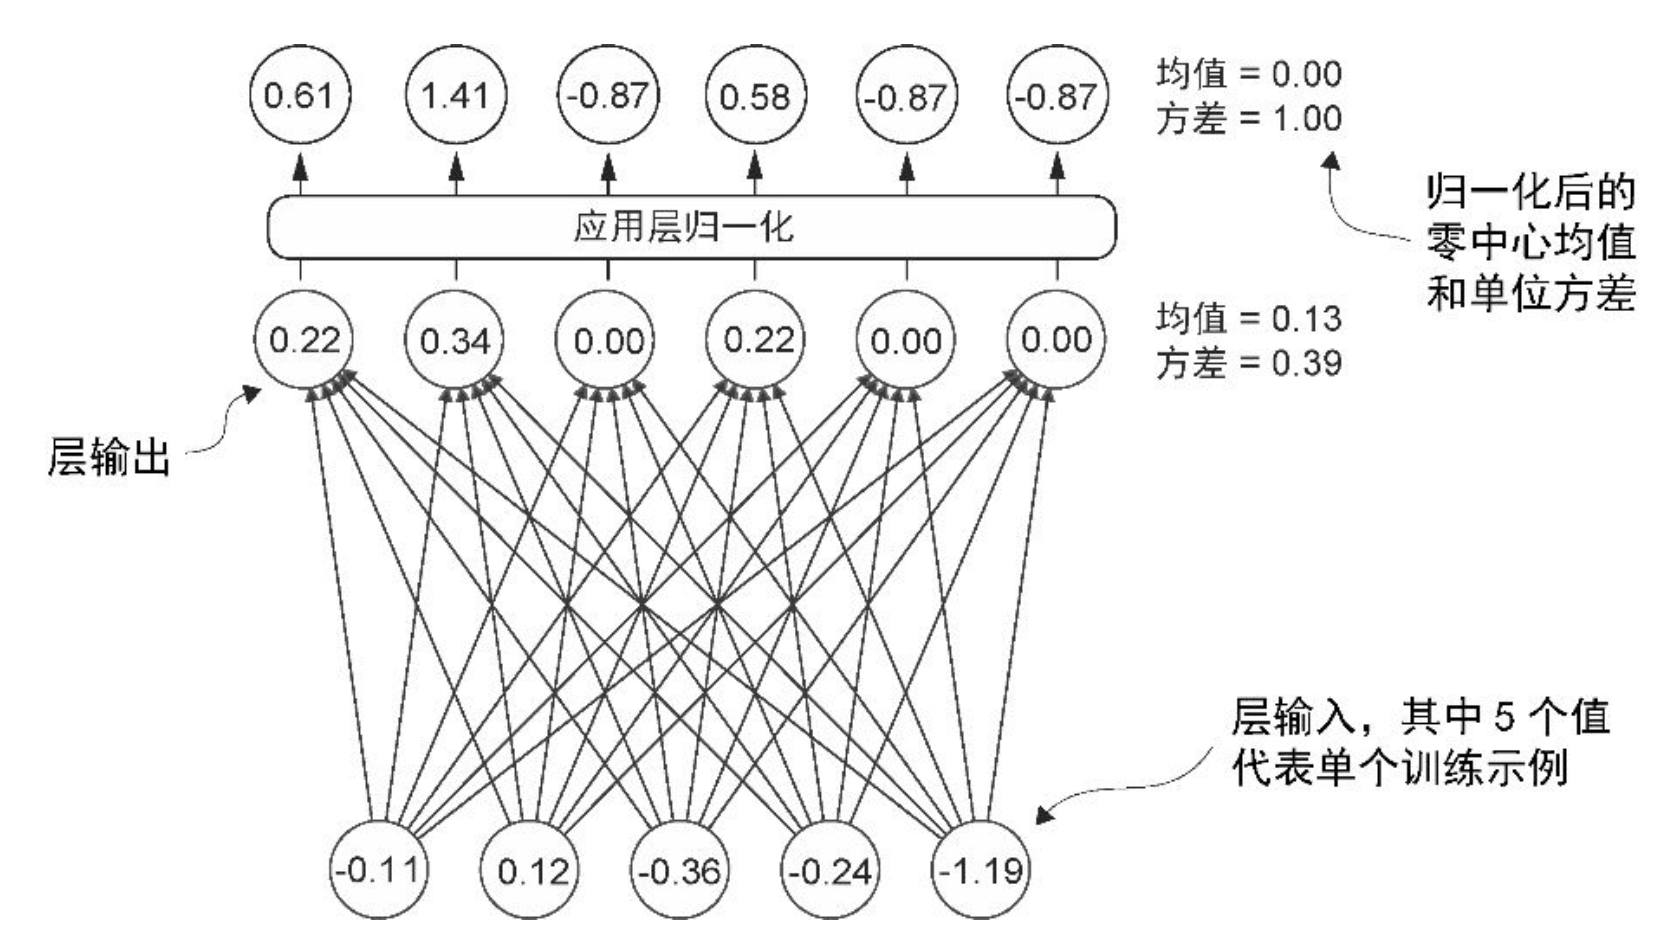

In [2]:
import torch
import torch.nn as nn

# 实现层归一化类
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        # 归一化时加到方差防止除零错误
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

In [3]:
# 测试LayerNorm模块
torch.manual_seed(123)
batch_example = torch.randn(2, 5)
ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[-2.9802e-08],
        [ 0.0000e+00]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


## GELU激活函数
GELU激活函数可以通过多种方式实现，其精确的定义为GELU(x)=x * &(x)，其中&(x)是标准高斯分布的累积分布函数。然而，在实际操作中，通常我们会使用一种计算量较小的近似实现（原始的GPT-2模型也是使用这种通过曲线拟合得到的近似方法进行训练的）：
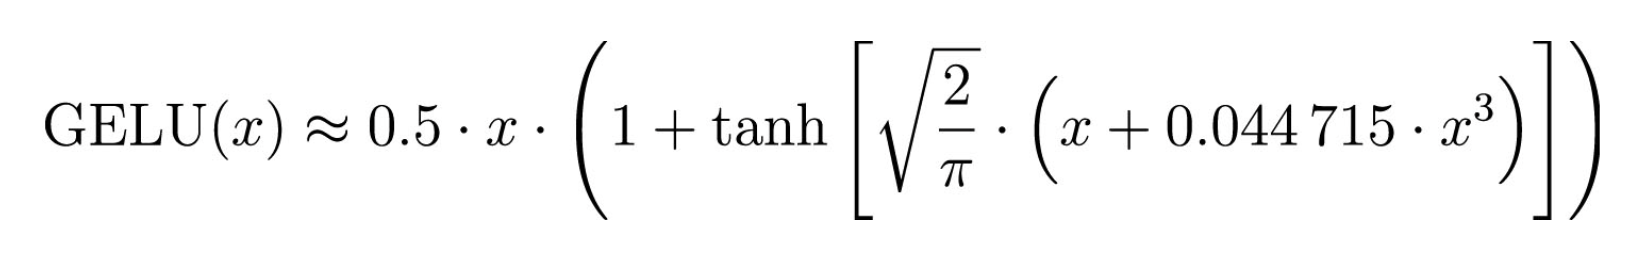

In [4]:
# 实现GELU激活函数
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
        ))

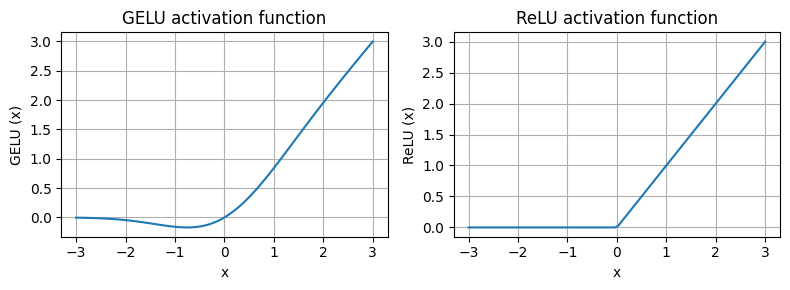

In [5]:
# 比较GELU和ReLU激活函数
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()
# 在-3和3之间创建100个样本数据点
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)
plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label} (x)")
    plt.grid(True)
plt.tight_layout()
plt.show()

## 前馈神经网络
前馈神经网络模块在提升模型学习和泛化能力方面非常关键。虽然该模块的输入和输出维度保持一致，但它通过第一个线性层将嵌入维度扩展到了更高的维度，如图所示。扩展之后，应用非线性GELU激活函数，然后通过第二个线性变换将维度缩回原始大小。这种设计允许模型探索更丰富的表示空间。
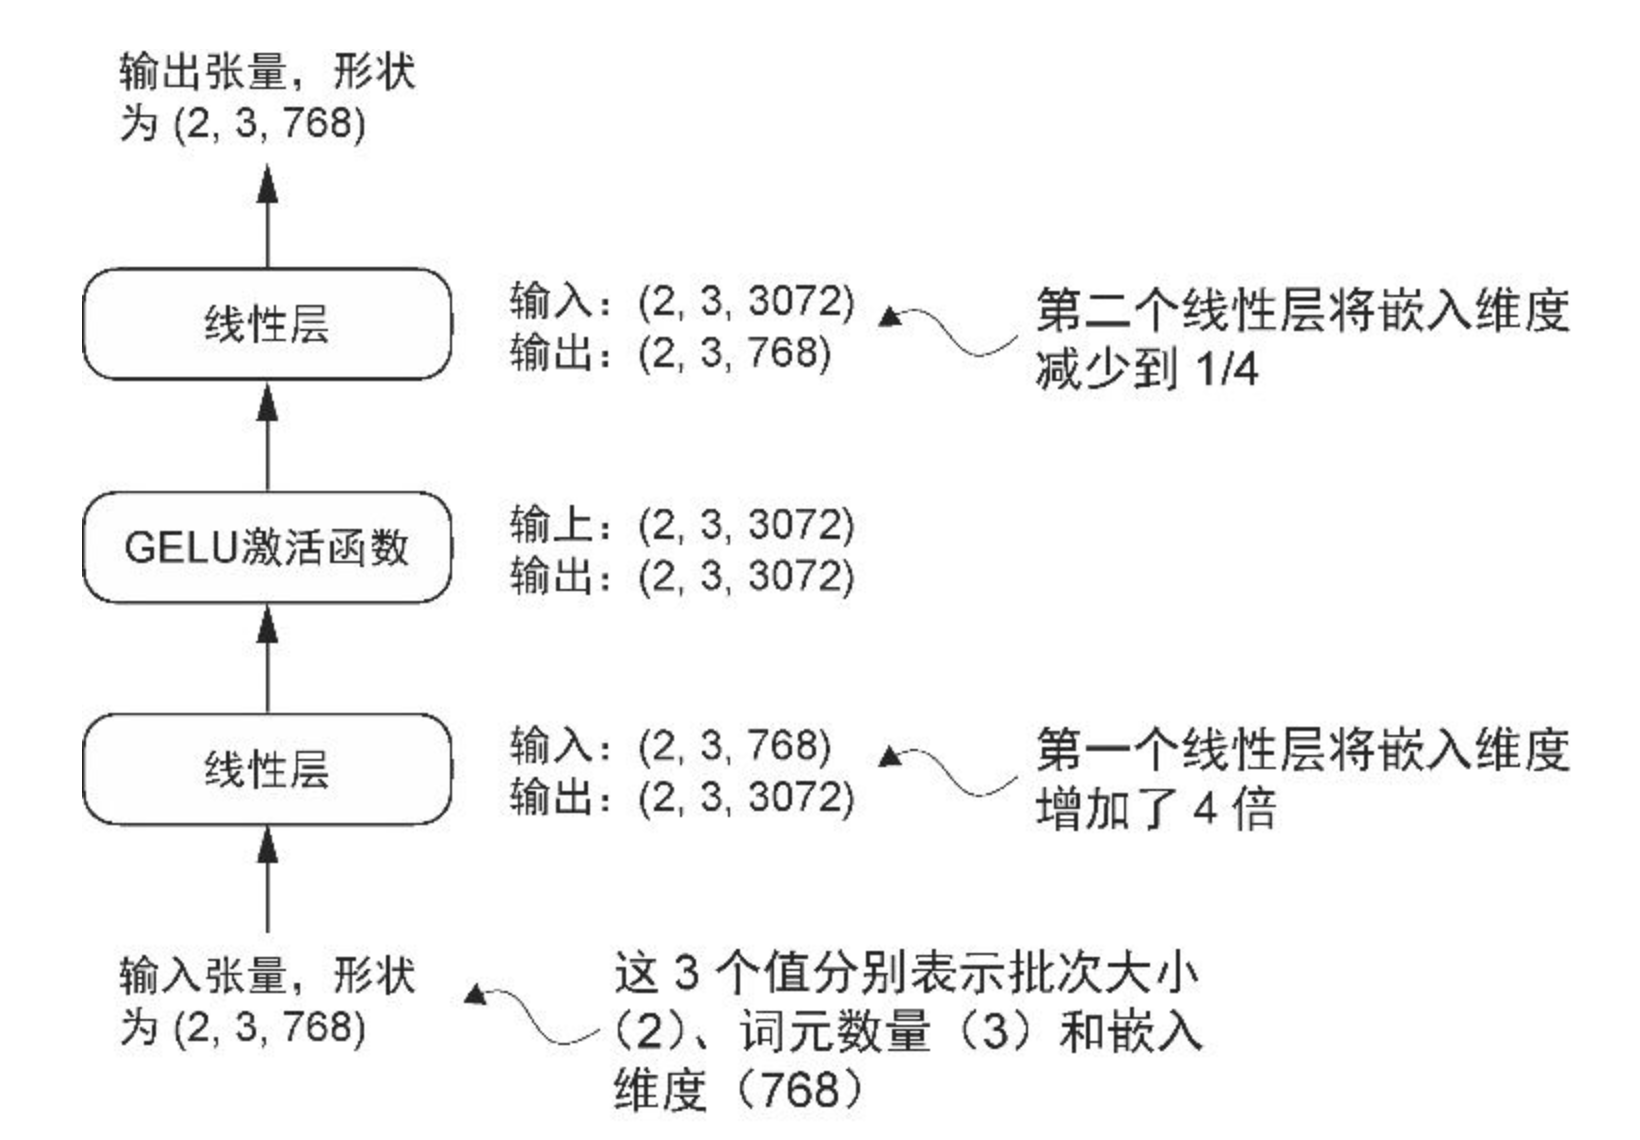

In [6]:
# 实现前馈神经网络模块
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4*cfg["emb_dim"]),
            GELU(),
            nn.Linear(4*cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)

In [7]:
# 测试前馈神经网络模块
ffn = FeedForward(GPT_CONFIG_124M)
x = torch.rand(2, 3, 768)
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


## 残差连接
残差连接最初用于计算机视觉中的深度网络（特别是残差网络），目的是缓解梯度消失问题。梯度消失问题指的是在训练过程中，梯度在反向传播时逐渐变小，导致早期网络层难以有效训练。
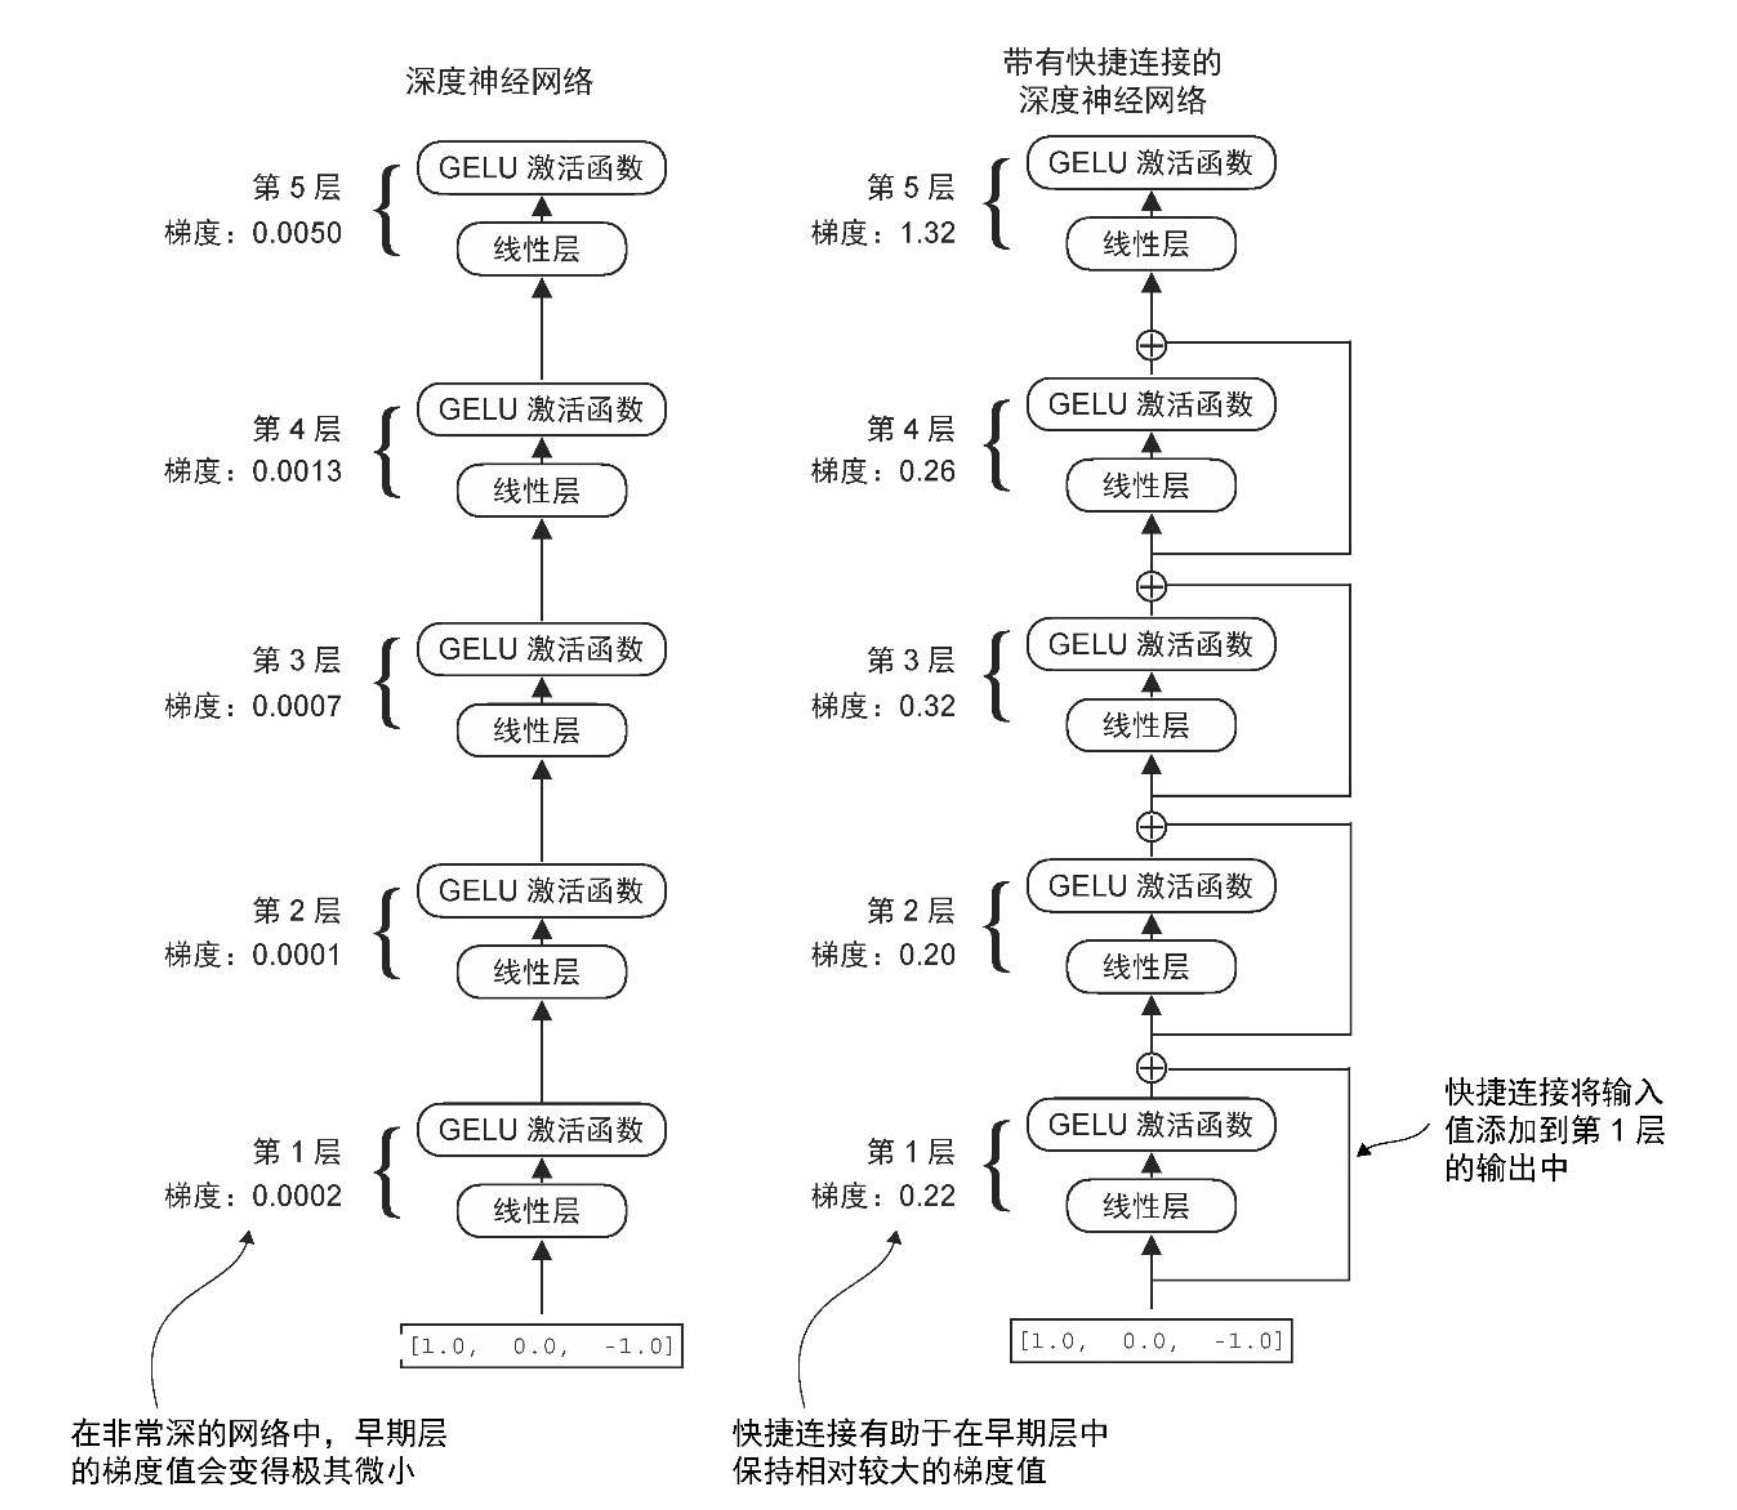

In [8]:
# 实现一个5层的神经网络演示残差连接
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        # 5个层的实现
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU()),
        ])

    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x

In [9]:
# 实现一个用于在模型的反向传播中计算梯度的函数
def print_gradients(model, x):
    # 前向传播
    output = model(x)
    target = torch.tensor([[0.]])
    # 基于目标和输出之间的差距来计算损失
    loss = nn.MSELoss()
    loss = loss(output, target)
    # 反向传播来计算梯度
    loss.backward()
    for name, param in model.named_parameters():
        if 'weight' in name:
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

In [10]:
# 初始化一个没有残差连接的神经网络
layer_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=False
)
# 应用于没有残差连接的模型，梯度在从最后一层layers.4到第一层layers.0的过程中逐渐变小，这种现象称为梯度消失
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173584925942123
layers.1.0.weight has gradient mean of 0.00012011159560643137
layers.2.0.weight has gradient mean of 0.0007152040489017963
layers.3.0.weight has gradient mean of 0.0013988736318424344
layers.4.0.weight has gradient mean of 0.005049645435065031


In [11]:
# 实例化一个包含残差连接的模型,可以看到梯度消失问题得到缓解
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169792652130127
layers.1.0.weight has gradient mean of 0.20694108307361603
layers.2.0.weight has gradient mean of 0.3289699852466583
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258541822433472


## Transformer块
Transformer块结合了多个组件，包括掩码多头注意力和前馈层。当Transformer块处理输入序列时，序列中的每个元素（如单词或子词）都被表示为一个固定大小的向量（此处为768维）。Transformer块内的操作，包括多头注意力和前馈层，旨在以保持这些向量维度的方式来转换它们。Transformer块的核心思想是，自注意力机制在多头注意力块中用于识别和分析输入序列中元素之间的关系。相比之下，前馈神经网络则在每个位置上对数据进行单独的修改。这种组合不仅提供了对输入更细致的理解和处理，而且提升了模型处理复杂数据模式的整体能力。
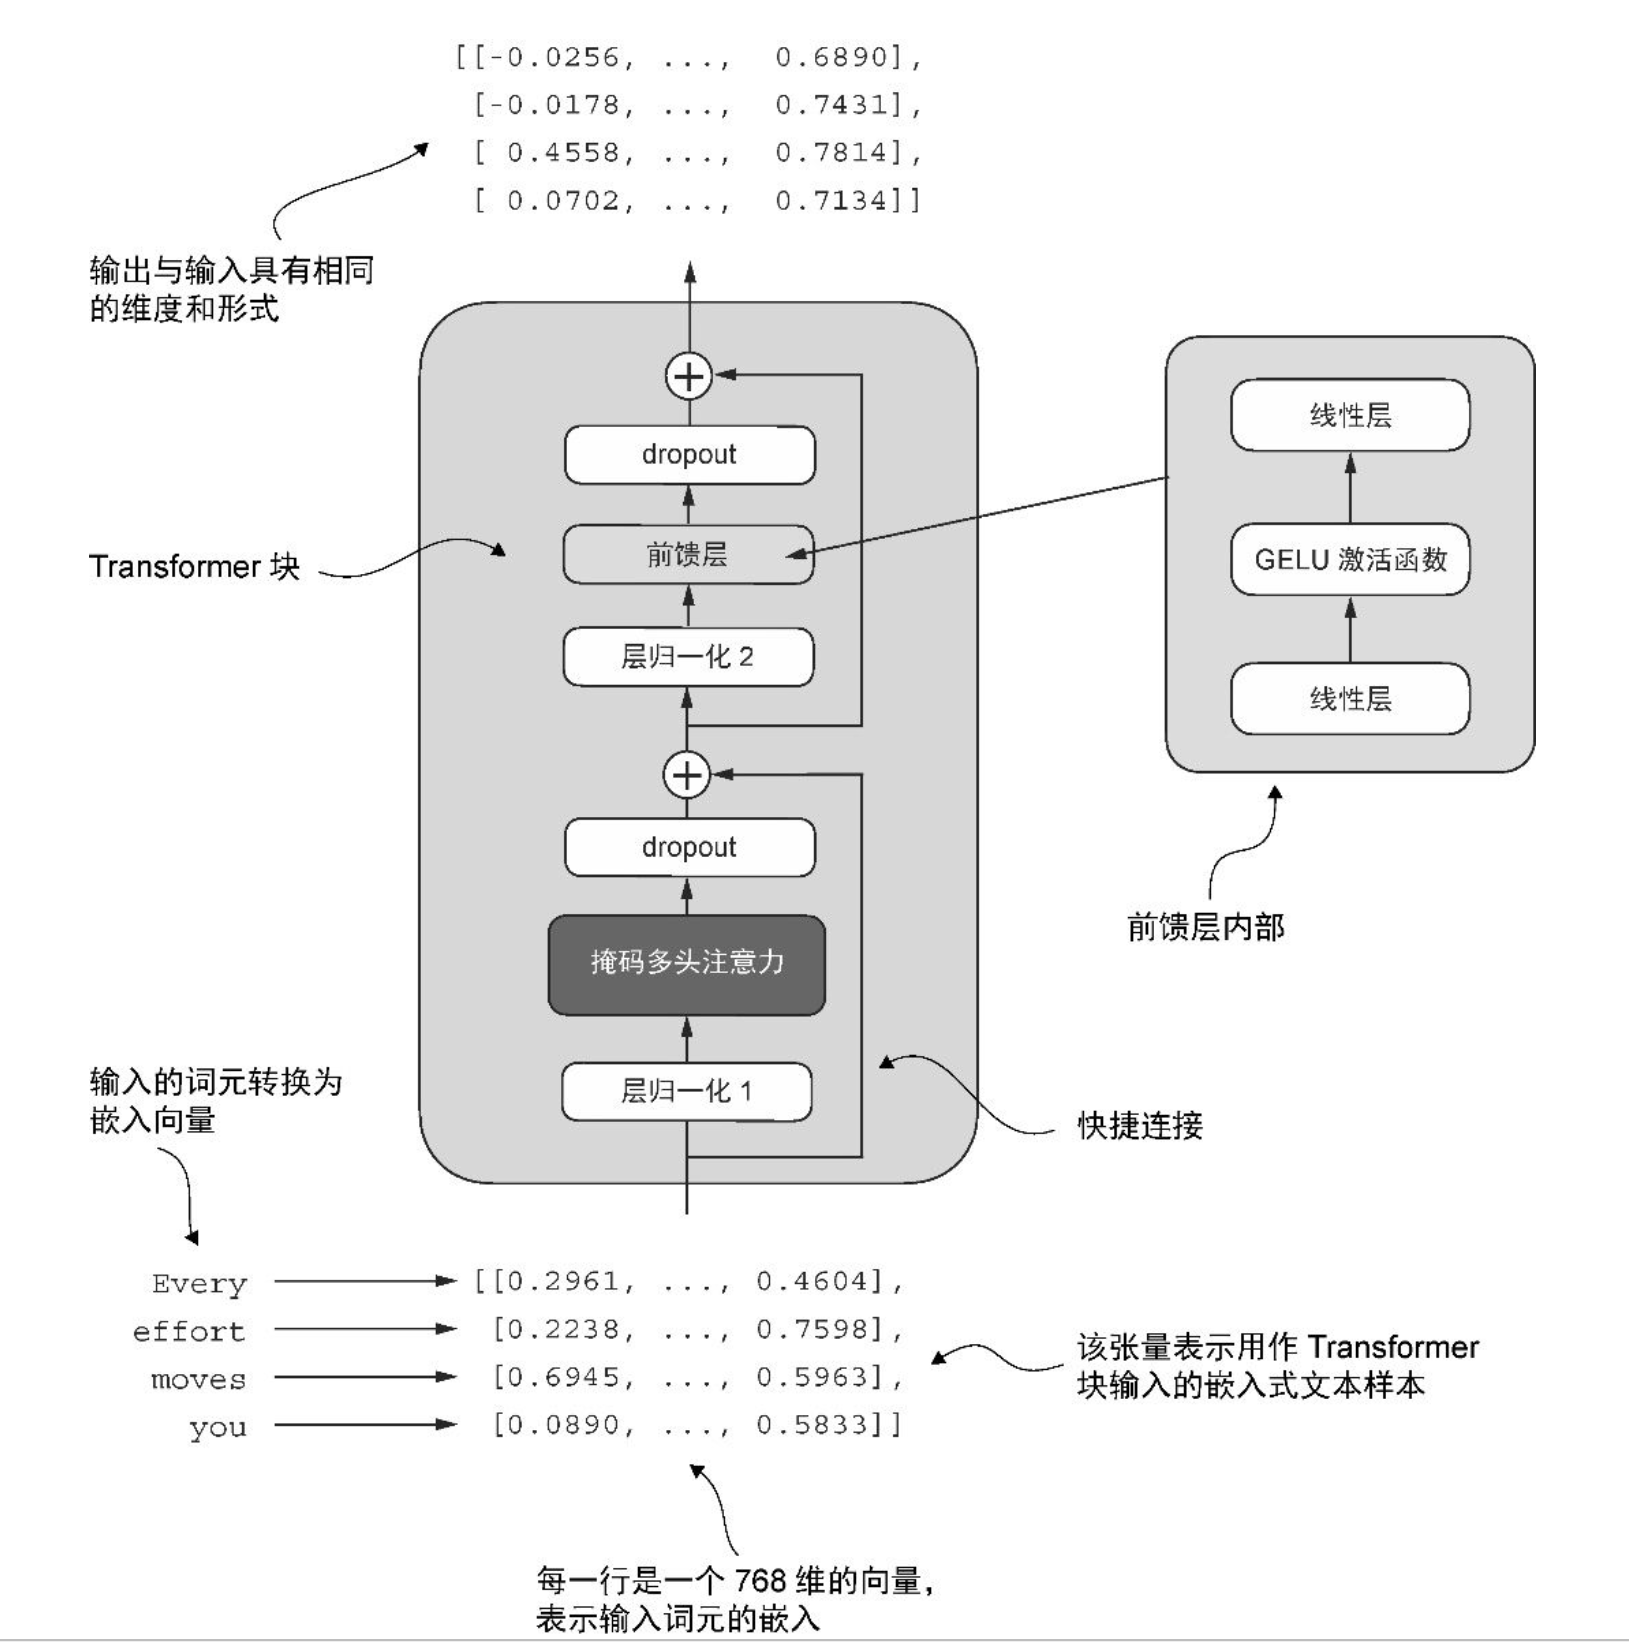

In [14]:
# 第三章的MultiHeadAttention
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        # 使用一个线性层来组合头的输出
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer('mask', torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        # 张量形状：(b, num_tokens, d_out)
        queries = self.W_query(x)
        keys = self.W_key(x)
        values = self.W_value(x)
        # 转换为(b, num_tokens, num_heads, head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        # 从形状(b, num_tokens, num_heads, head_dim)转换为(b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)
        # 计算每个头的点积，形状 (b, num_heads, num_tokens, num_tokens)
        attn_scores = queries @ keys.transpose(2, 3)
        # 使用掩码填充注意力分数
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores.masked_fill_(mask_bool, -torch.inf)
        # 计算注意力权重
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1
        )
        attn_weights = self.dropout(attn_weights)
        # 张量形状 (b, num_tokens, n_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)
        # 组合头 (b, num_tokens, d_out)
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        # 添加一个可选的线性投影
        context_vec = self.out_proj(context_vec)
        return context_vec

In [15]:
# 实现GPT的Transformer块组件
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # 在注意力块中添加残差连接
        short_cut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + short_cut
        # 在前馈层中添加残差连接
        short_cut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + short_cut
        return x

In [16]:
# 测试Transformer块
torch.manual_seed(123)
x = torch.rand(2, 4, 768)
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)
print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


## GPT-2模型架构
在用代码构建GPT-2模型之前，先来看看它的整体结构，如图所示，其中包括了我们到目前为止讨论的所有概念。可以看到，Transformer块在GPT模型架构中被多次重复。在参数量为1.24亿的GPT-2模型中，这个Transformer块被重复使用了12次，这可以通过GPT_CONFIG_124M字典中的n_layers条目进行指定。在最大规模的GPT-2模型（参数量为15.42亿）中，这个Transformer块被重复了48次。
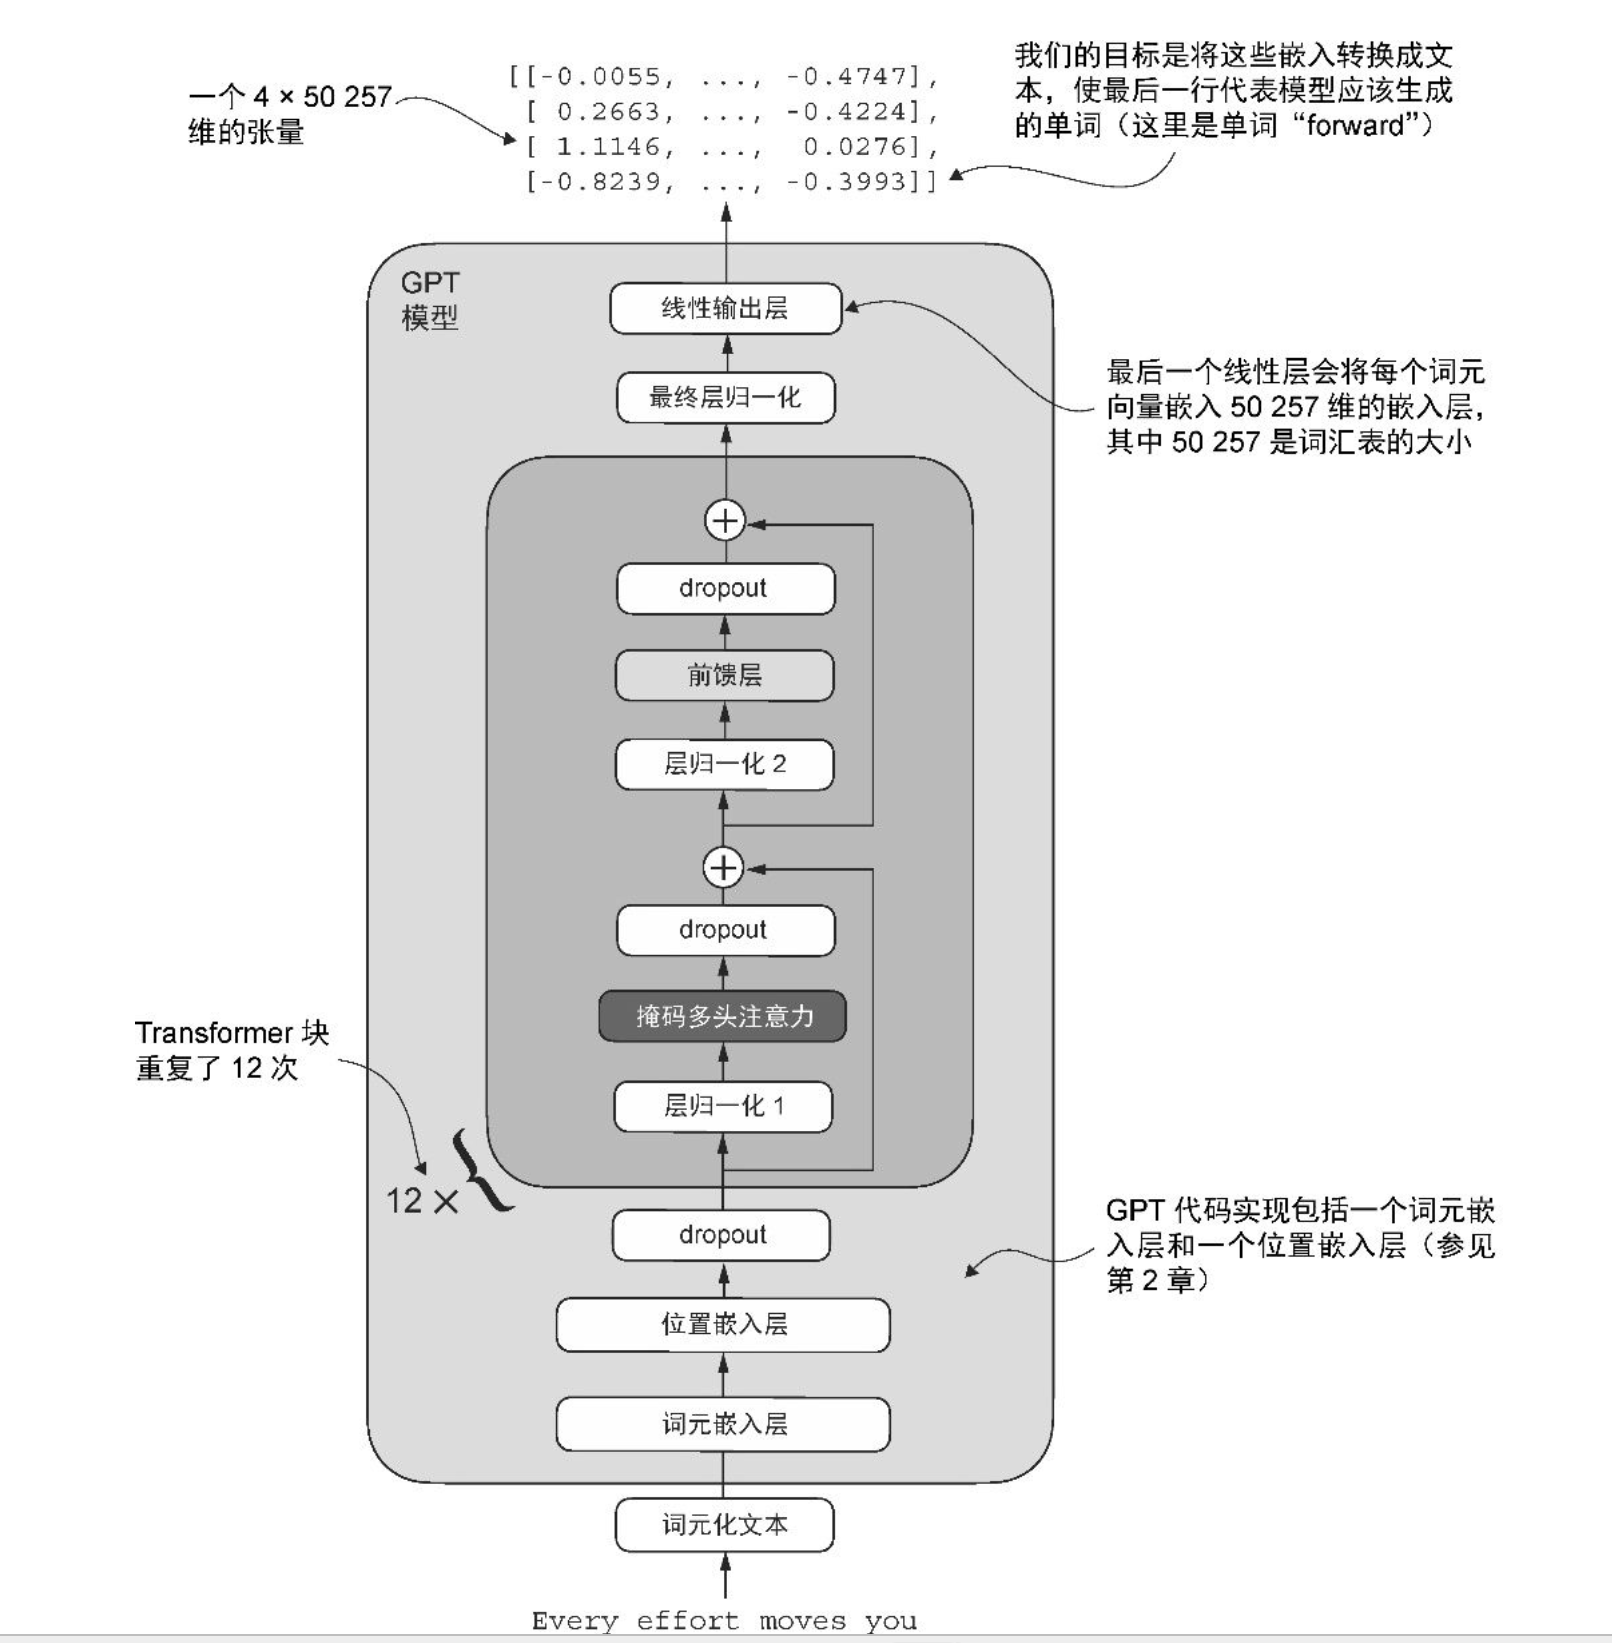

In [17]:
# 实现GPT模型架构
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [19]:
# 使用titoken分词器对包含两个文本输入的批次进行分词处理
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)

# 测试GPT模型
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.3613,  0.4222, -0.0711,  ...,  0.3483,  0.4661, -0.2838],
         [-0.1792, -0.5660, -0.9485,  ...,  0.0477,  0.5181, -0.3168],
         [ 0.7120,  0.0332,  0.1085,  ...,  0.1018, -0.4327, -0.2553],
         [-1.0076,  0.3418, -0.1190,  ...,  0.7195,  0.4023,  0.0532]],

        [[-0.2564,  0.0900,  0.0335,  ...,  0.2659,  0.4454, -0.6806],
         [ 0.1230,  0.3653, -0.2074,  ...,  0.7705,  0.2710,  0.2246],
         [ 1.0558,  1.0318, -0.2800,  ...,  0.6936,  0.3205, -0.3178],
         [-0.1565,  0.3926,  0.3288,  ...,  1.2630, -0.1858,  0.0388]]],
       grad_fn=<UnsafeViewBackward0>)


In [20]:
# 统计模型参数张量的总参数量
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


## 大模型生成文本
大语言模型逐步生成文本的过程，每次生成一个词元。从初始输入上下文(“Hello, I am”)开始，模型在每轮迭代中预测下一个词元，并将其添加到输入上下文中以进行下一轮预测。如图所示，第一轮迭代添加了“a”，第二轮迭代添加了“model”，第三轮迭代添加了“ready”，逐步形成了完整的句子
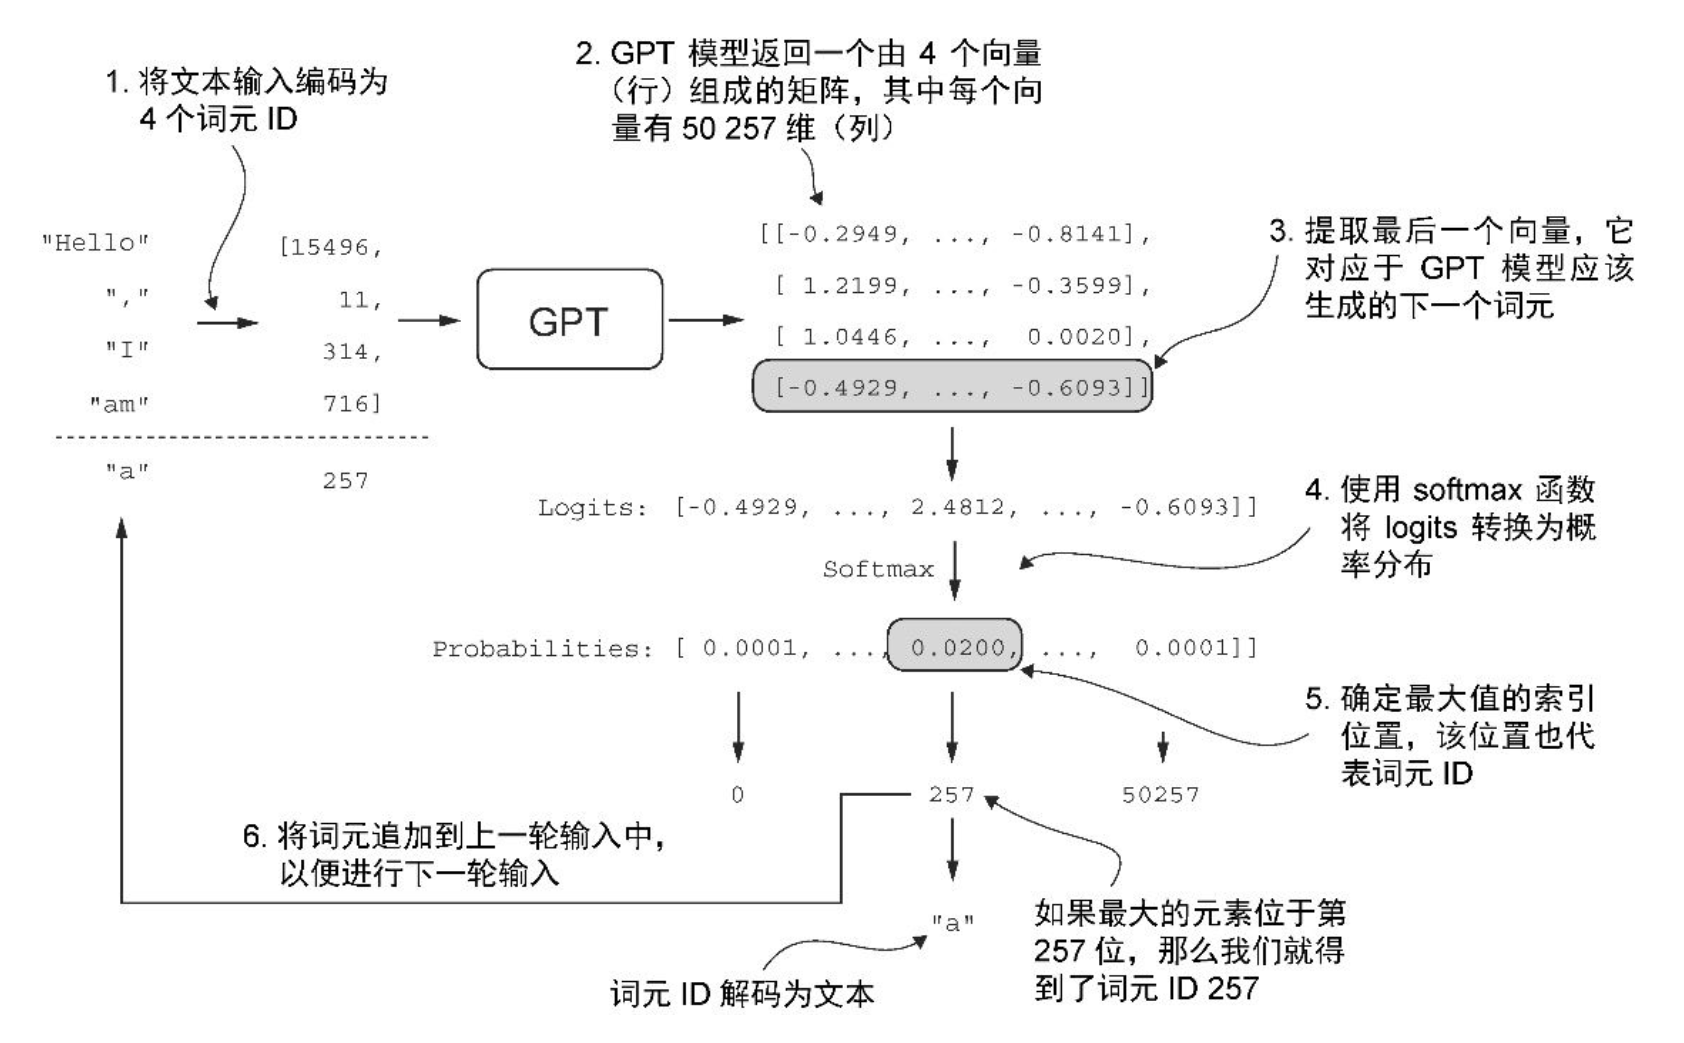

In [21]:
# GPT模型中用于生成文本的函数
def generate_text_simple(model, idx, max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        # 将当前文本截断至支持的长度
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        # 只关注最后一个输出的内容，形状由(batch, n_token, vocab_size)变为(batch, vocab_size)
        logits = logits[:, -1, :]
        probas = torch.softmax(logits, dim=-1)
        # idx_next的形状为(batch, 1)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)
        # 将计算出的下一字符索引添加到索引数组，idx形状变为(batch, n_toekns+1)
        idx = torch.cat((idx, idx_next), dim=1)
    return idx

In [22]:
# 测试模型生成文本
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded:", encoded)
# 添加batch维度
encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.sahpe", encoded_tensor.shape)
# 将模型设置为.eval模式，禁用诸如dropout等只在训练期间使用的随机组件
model.eval()
out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"]
)
print("Output:", out)
print("Output length:", len(out[0]))
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

encoded: [15496, 11, 314, 716]
encoded_tensor.sahpe torch.Size([1, 4])
Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 42348,  7267]])
Output length: 10
Hello, I am Featureiman Byeswickattribute argue
